# Volatility Dynamics 06c — Student-t emission HMM

Follow-up to **VD 011**: in 06b the diagonal-Gaussian HMM's validation log-likelihood rose monotonically to the edge of the K grid (K = 7). One explanation is emission misspecification: heavy tails force a Gaussian HMM to spend extra states on the tails. 06c replaces the emission with a **multivariate Student-t** (diagonal scale, per-state $\nu_k$, one latent scale per bar shared across fields, missing fields marginalized exactly) and keeps every other part of 06b unchanged.

$$x_t\mid S_t=k \sim t_{\nu_k}(\mu_k,\ \operatorname{diag}(s^2_k))$$

On synthetic heavy-tailed data with true $K=3$, the Gaussian HMM reproduces 06b's pattern (monotone to the grid edge, K = 7) while the Student-t HMM selects K = 3 and recovers $\nu\approx3$.

**Pre-registered (VD 012):**
1. **Primary — identical to 06b:** at $h=60$ min, $\text{logloss}(M3)-\text{logloss}(M1)<0$ with 95% day-bootstrap upper bound $<0$ and ≥ 20 unique held-out onset timestamps.
2. **K:** grid 2–10; *interior K* iff the selected K < 10 and validation LL/row at K = 10 is not above it.
3. **Emission:** Student-t fits better iff its validation LL/row at its selected K exceeds the Gaussian's at the Gaussian's selected K (both fitted here on identical sequences).

The emissions contain no displacement-from-VWAP variable, so no state here can be a displacement (R) regime, whatever K is.

In [1]:
from pathlib import Path
import json, os, sys, time, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 300)
pd.set_option('display.max_rows', 300)

load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH = DATA_ROOT / 'database' / 'research.duckdb'
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data_engineering.modeling import volatility_vd_b_core as vb
from data_engineering.modeling import volatility_hmm_states_b as hb
from data_engineering.modeling import volatility_hmm_states_c as hc
START = os.getenv('VD6C_START', '').strip() or None
END = os.getenv('VD6C_END', '').strip() or None
ASSETS = [x.strip().upper() for x in os.getenv('VD6C_ASSETS', '').split(',') if x.strip()]
TRAIN_FRACTION = float(os.getenv('VD6C_TRAIN_FRACTION', str(hb.DEFAULT_TRAIN_FRACTION)))
K_VALUES = tuple(int(x) for x in os.getenv('VD6C_K', ','.join(map(str, hc.DEFAULT_K))).split(',') if x.strip())
N_INIT = int(os.getenv('VD6C_N_INIT', str(hc.DEFAULT_N_INIT)))
N_INIT_GAUSS = int(os.getenv('VD6C_N_INIT_GAUSS', '1'))
RUN_GAUSSIAN = os.getenv('VD6C_RUN_GAUSSIAN', '1').strip().lower() not in {'0', 'false', 'no'}
MAX_ITER = int(os.getenv('VD6C_MAX_ITER', str(hc.DEFAULT_MAX_ITER)))
N_BOOT = int(os.getenv('VD6C_N_BOOT', '2000'))
N_SIMS = int(os.getenv('VD6C_N_SIMS', '30'))
OUT = PROJECT_ROOT / 'notebooks' / 'Volatility_Dynamics' / '06c'
OUT.mkdir(parents=True, exist_ok=True)
print('06b pipeline', hb.VERSION, '| 06c', hc.VERSION, hc.selftest())


06b pipeline 0.1.0 | 06c 0.1.0 {'digamma': True, 't_beats_gaussian_on_t_data': True, 'nu_recovered_small': True, 'scaled_fb_matches_logspace': True, 'gaussian_limit': True, 'duration_check_compatible': True}


In [2]:
def qident(name):
    return '"' + str(name).replace('"', '""') + '"'

def load_frame(columns, start=None, end=None, assets=None):
    cols = list(dict.fromkeys(['state_time', 'underlying', 'return_5m'] + list(columns)))
    where = []
    if start:
        ts = pd.Timestamp(start)
        ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
        where.append(f"state_time >= TIMESTAMPTZ '{ts.isoformat()}'")
    if end:
        ts = pd.Timestamp(end)
        ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
        where.append(f"state_time < TIMESTAMPTZ '{(ts + pd.Timedelta(days=1)).isoformat()}'")
    if assets:
        where.append('underlying IN (' + ','.join(repr(x) for x in assets) + ')')
    sql = ('SELECT ' + ', '.join(qident(c) for c in cols) + ' FROM time_series_feature_state'
           + ('' if not where else ' WHERE ' + ' AND '.join(where)) + ' ORDER BY underlying, state_time')
    con = duckdb.connect(str(DB_PATH), read_only=True)
    try:
        df = con.execute(sql).df()
    finally:
        con.close()
    if df.empty:
        raise RuntimeError('No rows found.')
    df['state_time'] = pd.to_datetime(df['state_time'], utc=True)
    if df.duplicated(['underlying', 'state_time']).any():
        raise RuntimeError('Duplicate asset/timestamp rows.')
    print(f'rows {len(df):,} | assets {sorted(df.underlying.unique())} | {df.state_time.min()} -> {df.state_time.max()}')
    return df.reset_index(drop=True)

def schema_columns():
    con = duckdb.connect(str(DB_PATH), read_only=True)
    try:
        return con.execute('DESCRIBE time_series_feature_state').df()
    finally:
        con.close()

schema = set(schema_columns()['column_name'].astype(str))
missing = set(hb.REQUIRED_COLUMNS) - schema
if missing:
    raise RuntimeError(f'missing columns: {missing}')
df = load_frame(list(hb.REQUIRED_COLUMNS), START, END, ASSETS)
grid = vb.build_grid(df)


rows 42,336 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP'] | 2026-09-19 08:00:00+00:00 -> 2026-10-10 07:55:00+00:00


In [3]:
E = hb.build_emissions(grid, include_l2=False)
split = hb.chronological_split(grid, TRAIN_FRACTION)
train_mask = grid.time_ns < split.test_start_ns
params = hb.fit_hour_normalizer(grid, E, train_mask)
Z = hb.apply_normalizer(grid, E, params)
fit_idx = hb.sequences(grid, grid.time_ns < split.valid_start_ns)
val_idx = hb.sequences(grid, (grid.time_ns >= split.valid_start_ns) & train_mask)
tr_idx = hb.sequences(grid, train_mask)
te_idx = hb.sequences(grid, ~train_mask)
seq_meta = pd.DataFrame([{'split': s, 'n_sequences': len(ix), 'rows': int(sum(map(len, ix)))}
                         for s, ix in [('fit', fit_idx), ('valid', val_idx), ('train', tr_idx), ('test', te_idx)]])
display(seq_meta)
print('test starts', pd.Timestamp(split.test_start_ns, tz='UTC'), '| validation starts', pd.Timestamp(split.valid_start_ns, tz='UTC'))


,split,n_sequences,rows
0,fit,7,23520
1,valid,7,6048
2,train,7,29568
3,test,7,12768


test starts 2026-10-04 00:00:00+00:00 | validation starts 2026-10-01 00:00:00+00:00


K=2: student_t valid ll/row -10.0259 | gaussian valid ll/row -10.2594
K=3: student_t valid ll/row -9.7544 | gaussian valid ll/row -10.1137
K=4: student_t valid ll/row -9.5657 | gaussian valid ll/row -9.9688
K=5: student_t valid ll/row -9.3616 | gaussian valid ll/row -9.7601
K=6: student_t valid ll/row -9.2630 | gaussian valid ll/row -9.5217
K=7: student_t valid ll/row -9.2385 | gaussian valid ll/row -9.5012
K=8: student_t valid ll/row -9.1322 | gaussian valid ll/row -9.5137
K=9: student_t valid ll/row -8.9504 | gaussian valid ll/row -9.2899
K=10: student_t valid ll/row -8.8690 | gaussian valid ll/row -9.0943
fit 595s | Student-t selected K = 10 | Gaussian selected K = 10
{
  "k_grid": [
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10
  ],
  "student_t_selected_K": 10,
  "student_t_interior_K": false,
  "student_t_valid_ll_per_row_selected": -8.869034966668579,
  "gaussian_selected_K": 10,
  "gaussian_interior_K": false,
  "gaussian_valid_ll_per_row_selected": -9.09426329

emission,gaussian,student_t
K,,
2,-10.2594,-10.0259
3,-10.1137,-9.7544
4,-9.9688,-9.5657
5,-9.7601,-9.3616
6,-9.5217,-9.2630
7,-9.5012,-9.2385
8,-9.5137,-9.1322
9,-9.2899,-8.9504
10,-9.0943,-8.8690


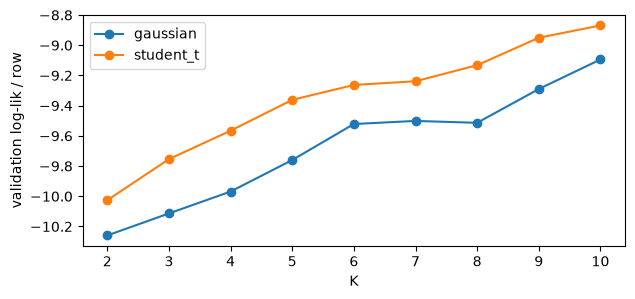

,log_range,log_volume,log_trades,log_book_updates,log_spread,atm_iv_dev,skew_dev,nu
state,,,,,,,,
0,0.29,0.10,0.22,0.20,0.28,1.12,-0.26,7.46
1,-0.00,-0.05,0.09,0.07,0.11,-0.70,0.20,10.38
2,0.26,0.31,0.44,0.37,0.08,0.16,-0.06,14.71
3,-0.71,-1.07,-0.64,-0.20,0.20,0.16,-0.08,9.22
4,0.80,0.14,0.58,-1.47,2.25,-0.01,0.60,5.24
5,-1.72,-1.18,-1.47,-1.74,-0.85,-1.50,0.23,9.71
6,-0.35,-0.00,-0.00,-0.23,0.04,0.02,0.05,2.31
7,0.42,1.44,1.65,0.52,-0.26,0.14,-0.20,3.81
8,-1.13,-1.45,-1.23,-1.72,-0.22,1.18,-0.26,7.74


,0,1,2,3,4,5,6,7,8,9
0,0.909,0.000,0.015,0.023,0.010,0.000,0.003,0.003,0.037,0.000
1,0.000,0.926,0.011,0.017,0.018,0.013,0.000,0.008,0.000,0.006
2,0.011,0.011,0.832,0.126,0.012,0.000,0.000,0.009,0.000,0.000
3,0.019,0.023,0.162,0.763,0.022,0.002,0.001,0.002,0.006,0.000
4,0.024,0.036,0.042,0.023,0.868,0.000,0.000,0.001,0.002,0.003
5,0.000,0.025,0.000,0.003,0.000,0.933,0.001,0.000,0.003,0.036
6,0.002,0.002,0.001,0.000,0.001,0.000,0.768,0.223,0.003,0.001
7,0.008,0.012,0.021,0.000,0.000,0.000,0.241,0.714,0.000,0.004
8,0.063,0.000,0.002,0.006,0.004,0.001,0.000,0.001,0.923,0.000
9,0.000,0.010,0.001,0.000,0.002,0.042,0.003,0.001,0.000,0.941


In [4]:
t0 = time.time()
comparison, model, k_t, k_g = hc.select_and_fit_both(
    [Z[i] for i in fit_idx], [Z[i] for i in val_idx], [Z[i] for i in tr_idx], K_VALUES,
    n_init=N_INIT, n_init_gauss=N_INIT_GAUSS, max_iter=MAX_ITER, run_gaussian=RUN_GAUSSIAN, progress=True)
print(f'fit {time.time()-t0:.0f}s | Student-t selected K = {k_t} | Gaussian selected K = {k_g}')
questions = hc.k_and_emission_questions(comparison, k_t, k_g)
print(json.dumps(questions, indent=2))
display(comparison.pivot(index='K', columns='emission', values='valid_loglik_per_row').round(4))
fig, ax = plt.subplots(figsize=(7, 3))
for em, g in comparison.groupby('emission'):
    ax.plot(g.K, g.valid_loglik_per_row, marker='o', label=em)
ax.set_xlabel('K'); ax.set_ylabel('validation log-lik / row'); ax.legend(); plt.show()
emis = pd.DataFrame(model.means, columns=E.columns).rename_axis('state')
emis['nu'] = model.nu
display(emis.round(2))
display(pd.DataFrame(model.A).round(3))


In [5]:
ft_train = hb.filtered_table(grid, model, tr_idx, Z, 'train')
ft_test = hb.filtered_table(grid, model, te_idx, Z, 'test')
thr = vb.q99_thresholds(grid, row_mask=train_mask)
tail = vb.tail_flags(grid, thr)
onset = vb.onset_flags(grid, tail)
labels, first_event = hb.future_onset_labels(grid, onset)
bench = hb.benchmark_features(grid)
def assemble(ft):
    t = ft.copy()
    t['underlying'] = [grid.assets[c] for c in grid.asset_code[t.row]]
    t['day'] = grid.day[t.row]
    t = pd.concat([t.reset_index(drop=True), labels.iloc[t.row].reset_index(drop=True), bench.iloc[t.row].reset_index(drop=True)], axis=1)
    return t[np.isfinite(t[list(hb.BENCHMARK_FEATURES)]).all(axis=1)].reset_index(drop=True)
tr_tab, te_tab = assemble(ft_train), assemble(ft_test)
test_onsets = np.flatnonzero(onset & ~train_mask)
n_unique_test = len(np.unique(grid.time_ns[test_onsets]))
print('test rows', len(te_tab), '| unique test onset timestamps', n_unique_test)
ft_test['underlying'] = [grid.assets[c] for c in grid.asset_code[ft_test.row]]
ft_test['state_time'] = pd.to_datetime(grid.time_ns[ft_test.row], utc=True)
display(pd.crosstab(ft_test.state_time.dt.date, ft_test.hard_state, normalize='index').round(2))
display(pd.crosstab(ft_test.underlying, ft_test.hard_state, normalize='index').round(2))


test rows 10092 | unique test onset timestamps 26


hard_state,0,1,2,3,4,5,6,7,8,9
state_time,,,,,,,,,,
2026-10-04,0.13,0.01,0.01,0.03,0.00,0.15,0.13,0.04,0.50,0.00
2026-10-05,0.21,0.10,0.15,0.10,0.02,0.05,0.11,0.20,0.03,0.04
2026-10-06,0.08,0.20,0.12,0.04,0.00,0.04,0.13,0.29,0.00,0.09
2026-10-07,0.13,0.09,0.14,0.05,0.01,0.00,0.16,0.40,0.02,0.00
2026-10-08,0.13,0.01,0.08,0.03,0.04,0.00,0.17,0.53,0.01,0.00
2026-10-09,0.00,0.03,0.02,0.04,0.01,0.04,0.21,0.38,0.00,0.26
2026-10-10,0.02,0.13,0.00,0.09,0.02,0.21,0.29,0.11,0.02,0.10


hard_state,0,1,2,3,4,5,6,7,8,9
underlying,,,,,,,,,,
AVAX,0.22,0.11,0.15,0.14,0.01,0.10,0.01,0.03,0.15,0.07
BTC,0.04,0.03,0.03,0.03,0.02,0.04,0.00,0.60,0.11,0.11
ETH,0.07,0.13,0.07,0.02,0.02,0.04,0.00,0.53,0.08,0.04
HYPE,0.24,0.08,0.13,0.04,0.02,0.01,0.10,0.14,0.10,0.12
SOL,0.09,0.08,0.09,0.04,0.01,0.08,0.00,0.42,0.10,0.08
TRX,0.02,0.03,0.02,0.04,0.00,0.00,0.73,0.15,0.01,0.00
XRP,0.07,0.08,0.08,0.04,0.01,0.09,0.28,0.23,0.07,0.03


In [6]:
state_cols = [f'p_state_{k}' for k in range(model.K)]
scores, boot = hb.benchmark_comparison(tr_tab, te_tab, state_cols, n_boot=N_BOOT)
decision = hb.hmm_decision(boot, n_unique_test)
display(scores.round(5)); display(boot.round(5))
print(json.dumps(decision, indent=2))
hazard = hb.state_hazard_with_events(te_tab, model.K, first_event, grid)
display(hazard[hazard.horizon_min == 60].round(4))


,horizon_min,model,n_test_rows,n_test_positive_rows,test_logloss,test_brier,test_auc
0,30,M0_base_rate,10092,248,0.12556,0.02482,0.50219
1,30,M1_vol_benchmark,10092,248,0.10518,0.02303,0.79367
2,30,M2_hmm_states,10092,248,0.12807,0.02593,0.71825
3,30,M3_benchmark_plus_hmm,10092,248,0.10894,0.02353,0.80544
4,60,M0_base_rate,10092,448,0.20140,0.04528,0.51608
5,60,M1_vol_benchmark,10092,448,0.16635,0.03987,0.76908
6,60,M2_hmm_states,10092,448,0.20904,0.04946,0.70086
7,60,M3_benchmark_plus_hmm,10092,448,0.17460,0.04191,0.78234
8,120,M0_base_rate,10092,758,0.30508,0.07846,0.54384
9,120,M1_vol_benchmark,10092,758,0.25421,0.06657,0.73051


,horizon_min,comparison,delta_logloss,boot_q025,boot_q975,n_test_days
0,30,M3_benchmark_plus_hmm - M1_vol_benchmark,0.00376,-0.00008,0.00674,7
1,30,M2_hmm_states - M0_base_rate,0.00251,-0.01058,0.01244,7
2,30,M1_vol_benchmark - M0_base_rate,-0.02038,-0.03115,-0.00927,7
3,60,M3_benchmark_plus_hmm - M1_vol_benchmark,0.00824,0.00017,0.01420,7
4,60,M2_hmm_states - M0_base_rate,0.00764,-0.01725,0.02651,7
5,60,M1_vol_benchmark - M0_base_rate,-0.03505,-0.05557,-0.01297,7
6,120,M3_benchmark_plus_hmm - M1_vol_benchmark,0.00808,-0.00397,0.01800,7
7,120,M2_hmm_states - M0_base_rate,0.00427,-0.03677,0.03298,7
8,120,M1_vol_benchmark - M0_base_rate,-0.05088,-0.08374,-0.01036,7


{
  "rule": "h=60m: logloss(M3)-logloss(M1) < 0 and day-bootstrap q97.5 < 0, >= 20 unique test onset timestamps",
  "delta_logloss": 0.00824213760143235,
  "boot_q975": 0.014202176786695504,
  "n_unique_test_onset_timestamps": 26,
  "status": "FAIL"
}


,horizon_min,state,baseline,soft_hazard,hard_hazard,hard_rows,distinct_events_behind_hard_hazard,distinct_event_timestamps,hard_lift
10,60,0,0.0444,0.0793,0.0813,1267,14,11,1.8313
11,60,1,0.0444,0.0178,0.0173,866,3,3,0.3902
12,60,2,0.0444,0.0277,0.0255,943,5,5,0.5733
13,60,3,0.0444,0.0286,0.0274,474,5,4,0.6178
14,60,4,0.0444,0.2845,0.3162,136,10,6,7.1224
15,60,5,0.0444,0.0103,0.0112,537,1,1,0.2517
16,60,6,0.0444,0.0317,0.0298,672,4,4,0.6704
17,60,7,0.0444,0.0640,0.0644,3480,31,17,1.4500
18,60,8,0.0444,0.0012,0.0000,937,0,0,0.0000
19,60,9,0.0444,0.0002,0.0000,780,0,0,0.0000


In [7]:
t0 = time.time()
dur_summary, dur_hazard = hb.duration_check(model, [Z[i] for i in te_idx], n_sims=N_SIMS)
print(f'duration simulation {time.time()-t0:.0f}s')
display(dur_summary.round(3))


duration simulation 5s


,state,self_transition,geometric_mean_bars,empirical_filtered_mean_run_bars,simulated_filtered_mean_run_q05,simulated_filtered_mean_run_q95,empirical_outside_sim_band
0,0,0.909,10.943,6.228,7.251,9.007,True
1,1,0.926,13.425,5.988,8.493,10.830,True
2,2,0.832,5.938,3.465,4.459,5.016,True
3,3,0.763,4.219,2.558,3.298,3.786,True
4,4,0.868,7.562,3.157,5.020,6.491,True
5,5,0.933,14.874,4.838,10.904,14.165,True
6,6,0.768,4.310,5.219,3.873,4.547,True
7,7,0.714,3.491,7.282,3.113,3.580,True
8,8,0.923,13.023,8.756,8.778,12.425,True
9,9,0.941,16.909,13.000,9.428,15.684,False


In [8]:
params.to_csv(OUT / '06c_hour_normalizer.csv', index=False)
seq_meta.to_csv(OUT / '06c_sequence_metadata.csv', index=False)
comparison.to_csv(OUT / '06c_k_selection_t_vs_gaussian.csv', index=False)
emis.reset_index().to_csv(OUT / '06c_emission_locations_and_nu.csv', index=False)
pd.DataFrame(np.sqrt(model.variances), columns=E.columns).rename_axis('state').reset_index().to_csv(OUT / '06c_emission_scales.csv', index=False)
pd.DataFrame(model.A).rename_axis('from_state').reset_index().to_csv(OUT / '06c_transitions.csv', index=False)
ft_test.to_csv(OUT / '06c_filtered_test.csv', index=False)
scores.to_csv(OUT / '06c_benchmark_scores.csv', index=False)
boot.to_csv(OUT / '06c_benchmark_bootstrap.csv', index=False)
hazard.to_csv(OUT / '06c_state_q99_hazard.csv', index=False)
dur_summary.to_csv(OUT / '06c_duration_summary.csv', index=False)
dur_hazard.to_csv(OUT / '06c_duration_hazard.csv', index=False)
(OUT / '06c_decision.json').write_text(json.dumps({'primary': decision, 'k_and_emission': questions}, indent=2))
meta = {
    'version': hc.VERSION, 'pipeline_version_06b': hb.VERSION, 'module': '06c_student_t_hmm',
    'emission': 'multivariate Student-t, diagonal scale, per-state nu, shared latent scale per bar, missing fields marginalized',
    'emissions': list(E.columns), 'k_grid': list(K_VALUES), 'n_init': N_INIT, 'n_init_gaussian': N_INIT_GAUSS,
    'student_t_selected_K': int(k_t), 'gaussian_selected_K': None if k_g is None else int(k_g),
    'nu_by_state': [float(v) for v in model.nu], 'train_fraction': TRAIN_FRACTION,
    'test_start': str(pd.Timestamp(split.test_start_ns, tz='UTC')), 'validation_start': str(pd.Timestamp(split.valid_start_ns, tz='UTC')),
    'n_unique_test_onset_timestamps': int(n_unique_test), 'decision': decision, 'k_and_emission': questions,
    'first_time': str(df.state_time.min()), 'last_time': str(df.state_time.max()), 'n_rows': int(len(df)),
}
(OUT / '06c_run_metadata.json').write_text(json.dumps(meta, indent=2))
print('wrote', OUT)


wrote D:\Projects\deribit_market_data\notebooks\Volatility_Dynamics\06c
